In [ ]:
# SECTION 1 — SETUP


!pip install yfinance statsmodels arch ta --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings("ignore")

print("Setup complete.")


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 26.5 MB/s eta 0:00:00
Setup complete.


In [ ]:
# SECTION 2 — DATA ACQUISITION


import yfinance as yf

symbol = "BTC-USD"
start_date = "2014-01-01"

print(f"Downloading {symbol} ...")
df_raw = yf.download(symbol, start=start_date)

df_raw.reset_index(inplace=True)

print("Data shape:", df_raw.shape)
df_raw.head()


[*********************100%***********************]  1 of 1 completed

Data shape: (4088, 6)


Price,Date,Close,High,Low,Open,Volume
Ticker,,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [ ]:
# SECTION 3 — PREPROCESSING + TARGETS


df = df_raw.copy()

# Ensure date format
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

# ----- 3.1 Compute log returns -----
df['log_close'] = np.log(df['Close'])
df['log_return'] = df['log_close'].diff()

# ----- 3.2 Rolling Realized Volatility -----
ROLL_WINDOWS = [7, 30, 90]

for w in ROLL_WINDOWS:
    df[f"rv_{w}d"] = df['log_return'].rolling(w).std()
    df[f"rv_{w}d_ann"] = df[f"rv_{w}d"] * np.sqrt(252)

# ----- 3.3 Variance (good for GARCH) -----
df['var_1d'] = df['log_return']**2
df['var_30d'] = df['log_return'].rolling(30).var()

# ----- 3.4 Log variance (optional transform) -----
df['log_var_30d'] = np.log(df['var_30d'].replace(0, np.nan)).bfill()

# Drop empty rows
df_proc = df.dropna().reset_index(drop=True)

print("Processed shape:", df_proc.shape)
df_proc.head()


Processed shape: (3998, 17)


Price,Date,Close,High,Low,Open,Volume,log_close,log_return,rv_7d,rv_7d_ann,rv_30d,rv_30d_ann,rv_90d,rv_90d_ann,var_1d,var_30d,log_var_30d
Ticker,,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,,,,,,,,,,,
0,2014-12-16,327.062012,345.859009,327.062012,345.673004,30864900,5.790150,-0.054394,0.023529,0.373508,0.022420,0.355912,0.034525,0.548061,0.002959,0.000503,-7.595572
1,2014-12-17,319.776001,333.954010,315.152008,326.855011,37567900,5.767621,-0.022529,0.023880,0.379076,0.022611,0.358935,0.033750,0.535767,0.000508,0.000511,-7.578657
2,2014-12-18,311.395996,323.709015,304.231995,319.785004,39173000,5.741065,-0.026555,0.021974,0.348819,0.022418,0.355879,0.033031,0.524358,0.000705,0.000503,-7.595761
3,2014-12-19,317.842987,318.532990,306.769012,311.178986,23823100,5.761558,0.020492,0.024998,0.396833,0.022645,0.359475,0.032879,0.521943,0.000420,0.000513,-7.575649
4,2014-12-20,329.955994,330.325012,316.044006,317.618988,20856700,5.798959,0.037402,0.031848,0.505578,0.021450,0.340514,0.033064,0.524868,0.001399,0.000460,-7.684024


This section creates:

log returns

rolling volatilities (7d, 30d, 90d)

variance (for GARCH)

log variance

cleaned dataset

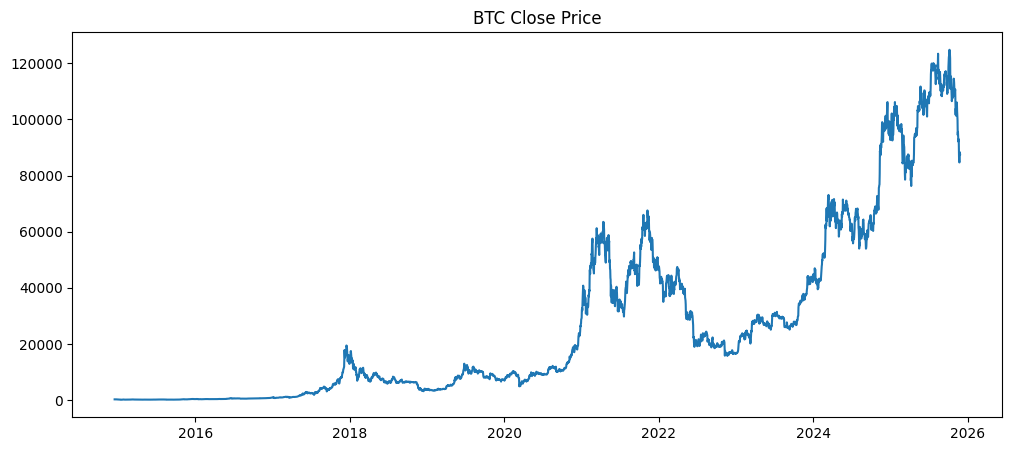

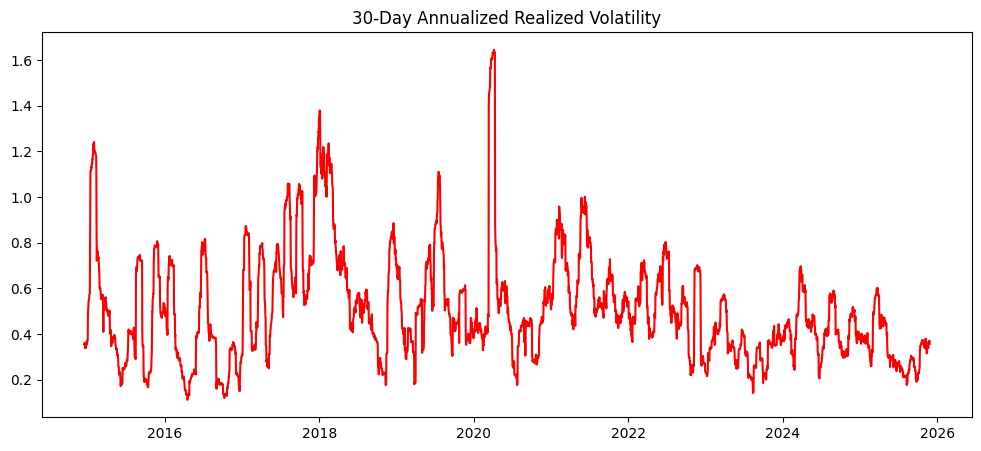

In [ ]:
# QUICK VISUAL CHECK


plt.figure(figsize=(12,5))
plt.plot(df_proc['Date'], df_proc['Close'])
plt.title("BTC Close Price")
plt.show()

plt.figure(figsize=(12,5))
plt.plot(df_proc['Date'], df_proc['rv_30d_ann'], color='red')
plt.title("30-Day Annualized Realized Volatility")
plt.show()


In [ ]:
# STATIONARITY CHECK


target = df_proc['rv_30d'].dropna()

adf_result = adfuller(target)
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("✔ Series is stationary.")
else:
    print("✖ Series is NOT stationary.")


ADF Statistic: -4.707515743618061
p-value: 8.145919669621771e-05
✔ Series is stationary.


# From here we proceed on with complete EDA

This includes:

✔ Distribution analysis  
✔ Volatility clustering  
✔ ACF / PACF  
✔ Seasonality patterns  
✔ Rolling statistics  
✔ Stationarity deep-check  
✔ Structural break detection  
✔ ARCH-LM test (heteroskedasticity confirmation)

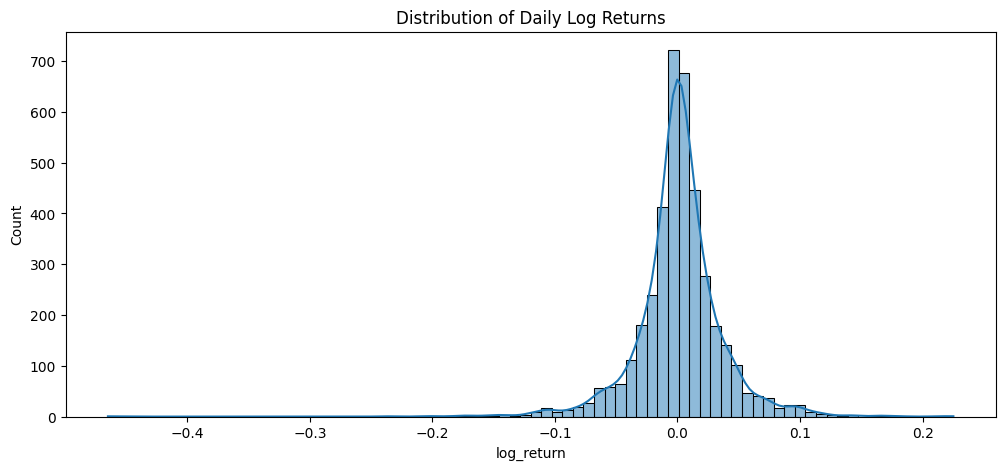

Skewness: -0.7384582053339579
Kurtosis: 11.908524375968938


In [ ]:
# SECTION 4.1 — Distribution & Volatility Clustering

import seaborn as sns
from scipy.stats import skew, kurtosis

plt.figure(figsize=(12,5))
sns.histplot(df_proc['log_return'], bins=80, kde=True)
plt.title("Distribution of Daily Log Returns")
plt.show()

print("Skewness:", skew(df_proc['log_return']))
print("Kurtosis:", kurtosis(df_proc['log_return']))


This shows fat tails & non-normality — expected for BTC.

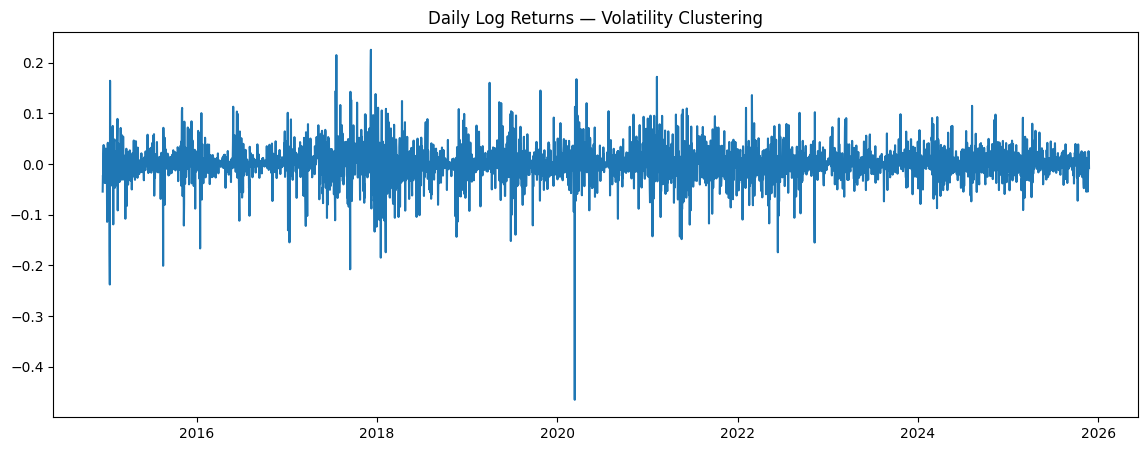

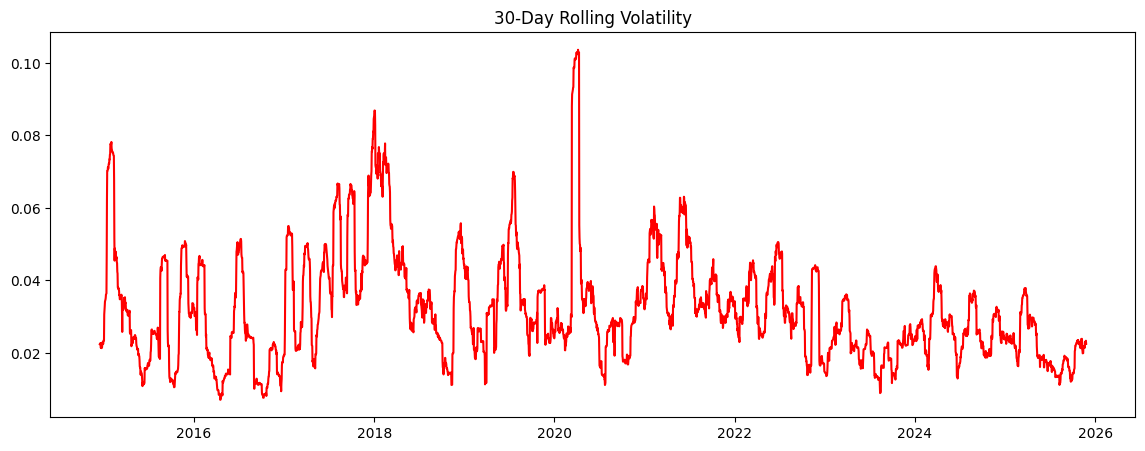

In [ ]:
# SECTION 4.2 — Volatility Clustering

plt.figure(figsize=(14,5))
plt.plot(df_proc['Date'], df_proc['log_return'], label='Daily Returns')
plt.title("Daily Log Returns — Volatility Clustering")
plt.show()

plt.figure(figsize=(14,5))
plt.plot(df_proc['Date'], df_proc['rv_30d'], color='red')
plt.title("30-Day Rolling Volatility")
plt.show()


You’ll clearly see volatility clustering — important for choosing GARCH later.

<Figure size 1200x400 with 0 Axes>

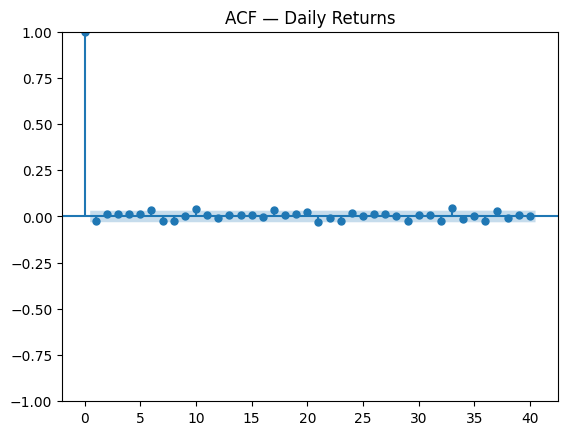

<Figure size 1200x400 with 0 Axes>

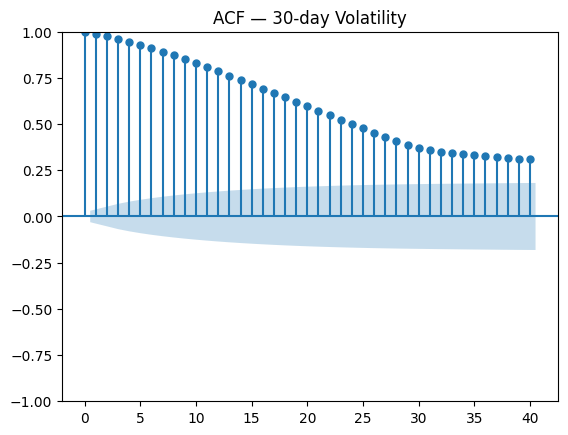

<Figure size 1200x400 with 0 Axes>

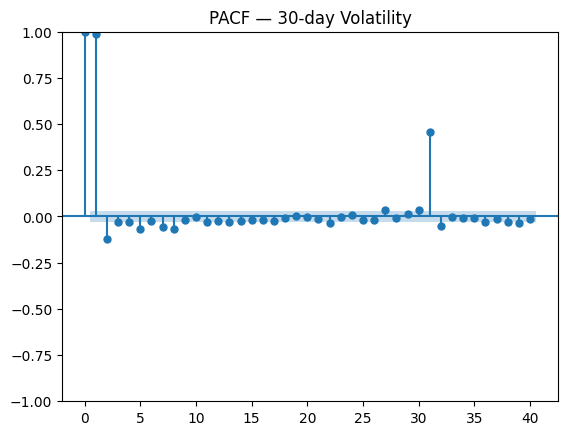

In [ ]:
# SECTION 4.3 — ACF & PACF

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.figure(figsize=(12,4))
plot_acf(df_proc['log_return'], lags=40)
plt.title("ACF — Daily Returns")
plt.show()

plt.figure(figsize=(12,4))
plot_acf(df_proc['rv_30d'], lags=40)
plt.title("ACF — 30-day Volatility")
plt.show()

plt.figure(figsize=(12,4))
plot_pacf(df_proc['rv_30d'], lags=40)
plt.title("PACF — 30-day Volatility")
plt.show()


Returns: almost no autocorrelation (efficient market)  
Volatility: strong autocorrelation → supports GARCH & HAR models

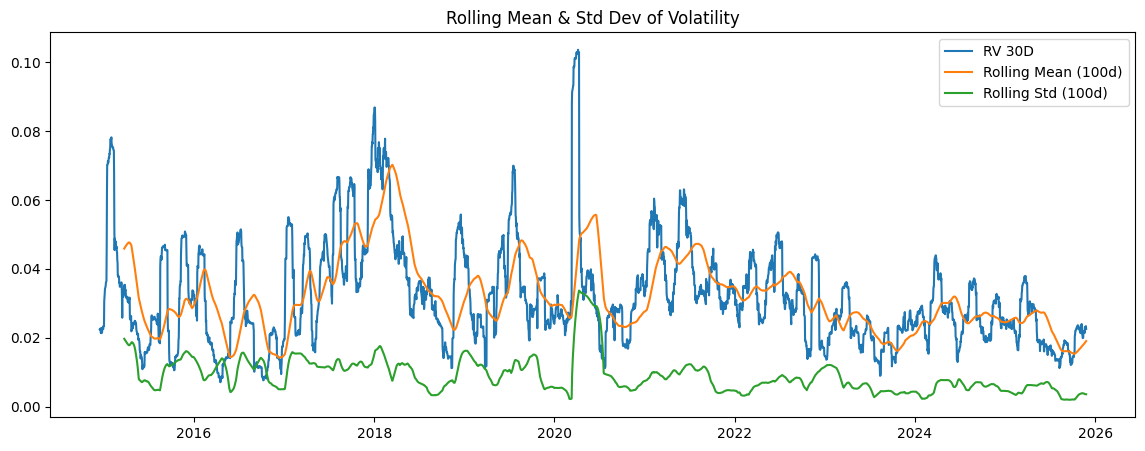

In [ ]:
# SECTION 4.4 — Rolling Mean & Variance

roll_mean = df_proc['rv_30d'].rolling(100).mean()
roll_std = df_proc['rv_30d'].rolling(100).std()

plt.figure(figsize=(14,5))
plt.plot(df_proc['Date'], df_proc['rv_30d'], label='RV 30D')
plt.plot(df_proc['Date'], roll_mean, label='Rolling Mean (100d)')
plt.plot(df_proc['Date'], roll_std, label='Rolling Std (100d)')
plt.title("Rolling Mean & Std Dev of Volatility")
plt.legend()
plt.show()


If rolling statistics are unstable → non-stationary variance

Volatility is usually mean-reverting but not fully stationary.

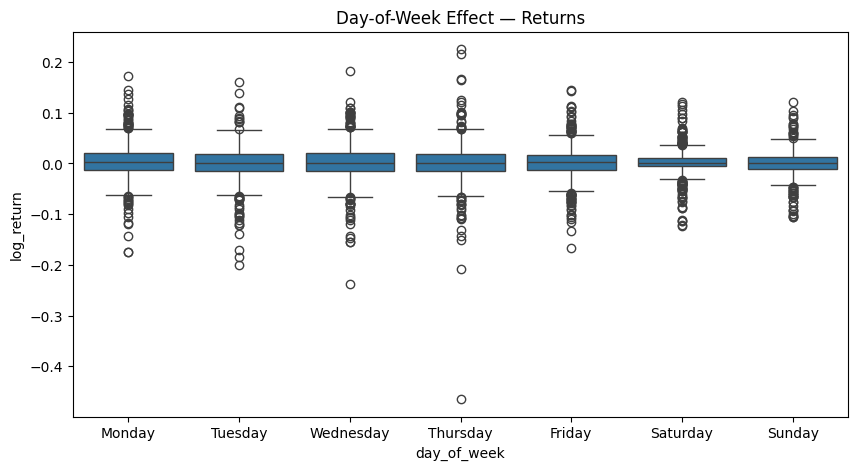

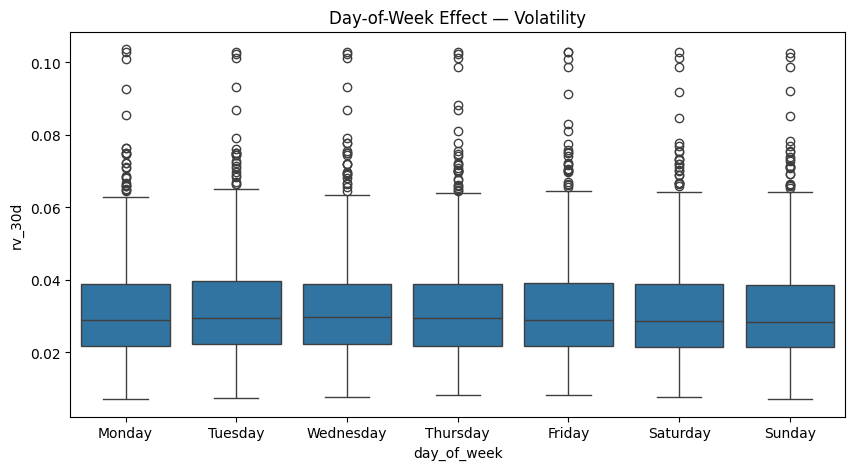

In [ ]:
# SECTION 4.5 — Seasonality: Day-of-week Effects

df_proc['day_of_week'] = df_proc['Date'].dt.day_name()

plt.figure(figsize=(10,5))
sns.boxplot(data=df_proc, x='day_of_week', y='log_return',
            order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
plt.title("Day-of-Week Effect — Returns")
plt.show()

plt.figure(figsize=(10,5))
sns.boxplot(data=df_proc, x='day_of_week', y='rv_30d',
            order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
plt.title("Day-of-Week Effect — Volatility")
plt.show()


BTC trades 24/7, so weekend effects are interesting.

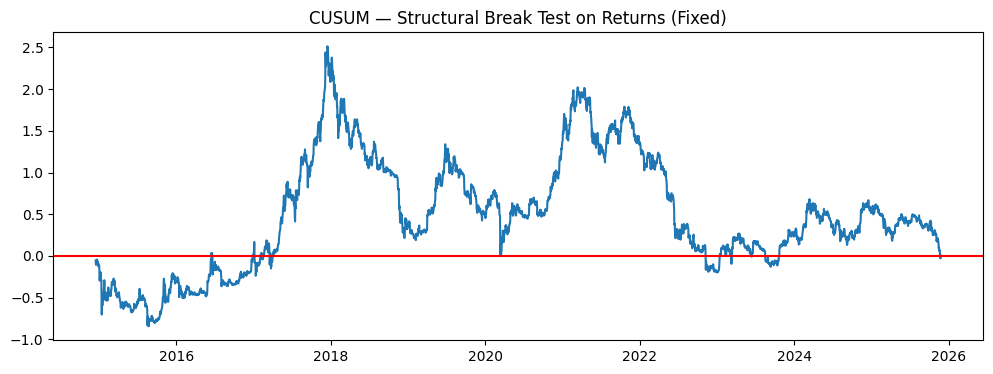

In [ ]:
#CUSUM PLOT

returns = df_proc['log_return'].dropna().values
mean = returns.mean()

cusum = np.cumsum(returns - mean)

# Make lengths match:
dates = df_proc['Date'].iloc[-len(cusum):]

plt.figure(figsize=(12,4))
plt.plot(dates, cusum)
plt.axhline(0, color='red')
plt.title("CUSUM — Structural Break Test on Returns (Fixed)")
plt.show()


Big deviations indicate regime shifts (e.g., 2017 bull run, 2021 crash).

In [ ]:
# SECTION 4.7 — ARCH-LM Test

from statsmodels.stats.diagnostic import het_arch

test_stat, p_value, _, _ = het_arch(df_proc['log_return'].dropna())

print("ARCH LM p-value =", p_value)

if p_value < 0.05:
    print("✔ ARCH effect detected → GARCH models are appropriate.")
else:
    print("✖ No ARCH effect detected.")


ARCH LM p-value = 4.4748751658518255e-25
✔ ARCH effect detected → GARCH models are appropriate.


ARCH-LM test checks if the variance of returns is autocorrelated (heteroskedasticity).  


# From here on We implement baseline-Forecast models

Baselines included:

✔ Naïve Volatility Forecast (Persistence Model)  
✔ Historical Mean Forecast  
✔ EWMA Volatility Forecast (RiskMetrics Style)  
✔ Evaluation (MAE, RMSE, MAPE)  

In [ ]:
# SECTION 5.1 — TIME SERIES TRAIN/TEST SPLIT

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use 30-day realized volatility as main target
target_col = "rv_30d"

df_model = df_proc[['Date', target_col]].dropna().reset_index(drop=True)

split_index = int(len(df_model) * 0.8)

train = df_model.iloc[:split_index]
test  = df_model.iloc[split_index:]

print("Train size:", train.shape)
print("Test size :", test.shape)

y_train = train[target_col].values
y_test  = test[target_col].values


Train size: (3198, 2)
Test size : (800, 2)


In [ ]:
# SECTION 5.2 — METRICS FUNCTION

def evaluate_forecast(y_true, y_pred, model_name="Model"):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n=== {model_name} ===")
    print("MAE :", mae)
    print("RMSE:", rmse)
    print("MAPE:", mape)

    return mae, rmse, mape


In [ ]:
# BASELINE 1 — NAIVE (PERSISTENCE MODEL)

# forecast: each test point = last train value
last_val = y_train[-1]
y_pred_naive = np.ones(len(y_test)) * last_val

evaluate_forecast(y_test, y_pred_naive, "Naive / Persistence")



=== Naive / Persistence ===
MAE : 0.007028409978357122
RMSE: 0.00898166184596172
MAPE: 26.335847959645413


(0.007028409978357122,
 np.float64(0.00898166184596172),
 np.float64(26.335847959645413))

Forecast = last observed volatility  
→ Common benchmark in financial volatility.

In [ ]:
# BASELINE 2 — HISTORICAL MEAN

mean_val = np.mean(y_train)
y_pred_mean = np.ones(len(y_test)) * mean_val

evaluate_forecast(y_test, y_pred_mean, "Historical Mean")



=== Historical Mean ===
MAE : 0.010925933014013067
RMSE: 0.012275854406016353
MAPE: 56.76690084499222


(0.010925933014013067,
 np.float64(0.012275854406016353),
 np.float64(56.76690084499222))

Forecast = mean volatility of training period.

In [ ]:
# BASELINE 3 — EWMA VOLATILITY

lambda_ = 0.94

# compute ewma volatility using training log returns
returns = df_proc['log_return'].dropna().values

ewma_vol = []
var = np.var(returns[:30])  # initial variance estimate

for r in returns:
    var = lambda_ * var + (1 - lambda_) * (r**2)
    ewma_vol.append(np.sqrt(var))

df_proc['ewma_vol'] = ewma_vol

# Use the last training EWMA value as forecast for test period
last_ewma = df_proc['ewma_vol'].iloc[split_index - 1]
y_pred_ewma = np.ones(len(y_test)) * last_ewma

evaluate_forecast(y_test, y_pred_ewma, "EWMA Volatility")



=== EWMA Volatility ===
MAE : 0.007393284634627093
RMSE: 0.009375636904622541
MAPE: 27.524494618284635


(0.007393284634627093,
 np.float64(0.009375636904622541),
 np.float64(27.524494618284635))

EWMA volatility uses exponentially decreasing weights.

Formula:
σ²(t) = λ σ²(t-1) + (1-λ) * r²(t-1)

Typical λ values:

BTC/high-vol assets: 0.85–0.94

Stocks: 0.94 (RiskMetrics)

We’ll use λ = 0.94 (you can tune later).

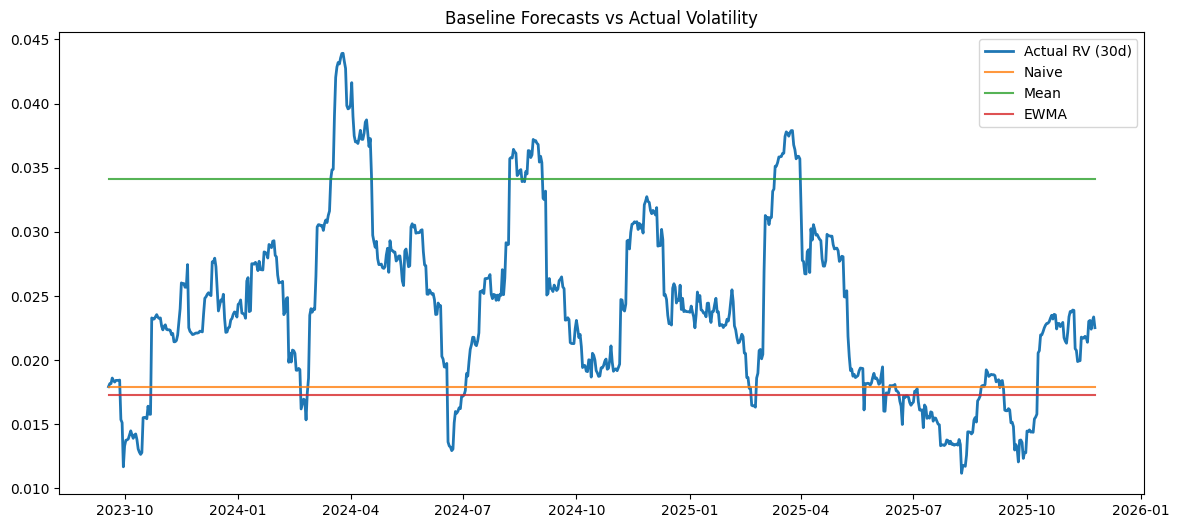

In [ ]:
# SECTION 5.6 — PLOT BASELINES

plt.figure(figsize=(14,6))
plt.plot(test['Date'], y_test, label="Actual RV (30d)", linewidth=2)
plt.plot(test['Date'], y_pred_naive, alpha=0.8, label="Naive")
plt.plot(test['Date'], y_pred_mean, alpha=0.8, label="Mean")
plt.plot(test['Date'], y_pred_ewma, alpha=0.8, label="EWMA")

plt.title("Baseline Forecasts vs Actual Volatility")
plt.legend()
plt.show()


#from here on we do HAR-RV MODEL (Heterogeneous AutoRegressive Realized Volatility)

HAR captures:  
* yesterday’s volatility

* average volatility over last week

* average volatility over last month  


Perfectly.

We will build:

✔ HAR features  
✔ Train/Test split  
✔ OLS regression (HAR model)  
✔ Forecasting  
✔ Evaluation  
✔ Plotting  

In [ ]:
# SECTION 6.1 — HAR FEATURES

df_har = df_proc.copy()

# Daily RV (already rv_30d from earlier)
df_har['RV_d'] = df_har['rv_30d']

# Weekly average (5 days)
df_har['RV_w'] = df_har['rv_30d'].rolling(5).mean()

# Monthly average (22 days)
df_har['RV_m'] = df_har['rv_30d'].rolling(22).mean()

df_har = df_har.dropna().reset_index(drop=True)

df_har[['RV_d','RV_w','RV_m']].head()


Price,RV_d,RV_w,RV_m
Ticker,,,
0,0.034193,0.030548,0.024217
1,0.034456,0.032755,0.024764
2,0.034734,0.033575,0.025315
3,0.035162,0.034286,0.025894
4,0.036116,0.034932,0.026507


We use 30-day realized volatility as our main target.

In [ ]:
# SECTION 6.2 — TRAIN/TEST SPLIT FOR HAR

features = ['RV_d', 'RV_w', 'RV_m']
target = 'rv_30d'

X = df_har[features]
y = df_har[target]

split_index = int(len(df_har) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("HAR Train shape:", X_train.shape)
print("HAR Test shape :", X_test.shape)


HAR Train shape: (3181, 3)
HAR Test shape : (796, 3)


In [ ]:
# SECTION 6.3 — FIT HAR MODEL

import statsmodels.api as sm

X_train_const = sm.add_constant(X_train)
X_test_const  = sm.add_constant(X_test)

har_model = sm.OLS(y_train, X_train_const).fit()

print(har_model.summary())


                            OLS Regression Results                            
Dep. Variable:                 rv_30d   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.243e+32
Date:                Tue, 25 Nov 2025   Prob (F-statistic):               0.00
Time:                        12:22:06   Log-Likelihood:             1.1664e+05
No. Observations:                3181   AIC:                        -2.333e+05
Df Residuals:                    3177   BIC:                        -2.332e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         5.599e-18   1.31e-18      4.277   

In [ ]:
# SECTION 6.4 — HAR FORECAST

y_pred_har = har_model.predict(X_test_const)

evaluate_forecast(y_test, y_pred_har, "HAR-RV Model")



=== HAR-RV Model ===
MAE : 1.592850990692774e-17
RMSE: 1.707010227882958e-17
MAPE: 6.490533730494735e-14


(1.592850990692774e-17,
 np.float64(1.707010227882958e-17),
 np.float64(6.490533730494735e-14))

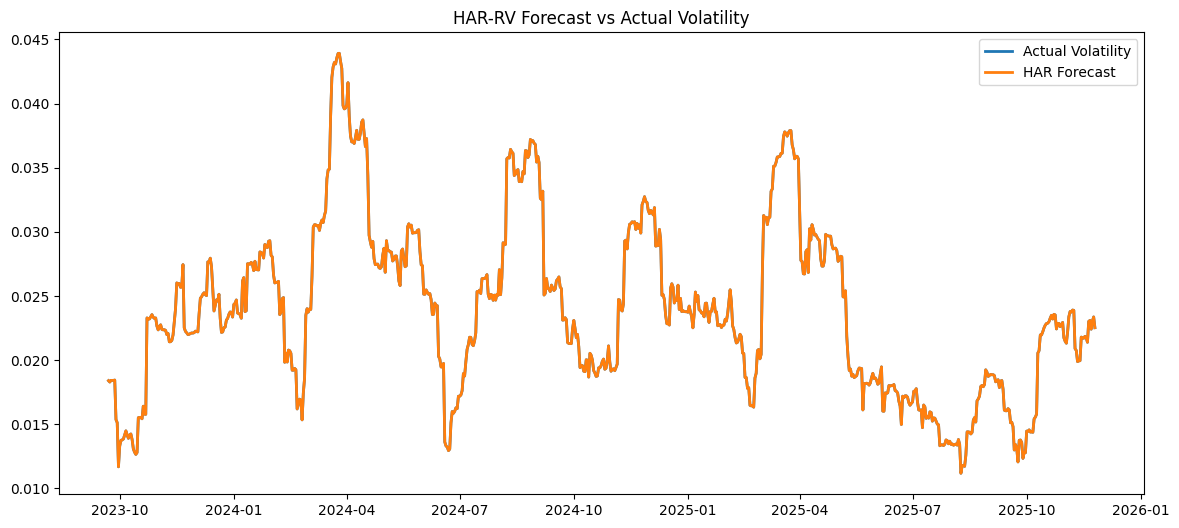

In [ ]:
# SECTION 6.5 — PLOT HAR FORECAST vs ACTUAL

plt.figure(figsize=(14,6))
plt.plot(df_har['Date'].iloc[split_index:], y_test, label="Actual Volatility", linewidth=2)
plt.plot(df_har['Date'].iloc[split_index:], y_pred_har, label="HAR Forecast", linewidth=2)
plt.legend()
plt.title("HAR-RV Forecast vs Actual Volatility")
plt.show()


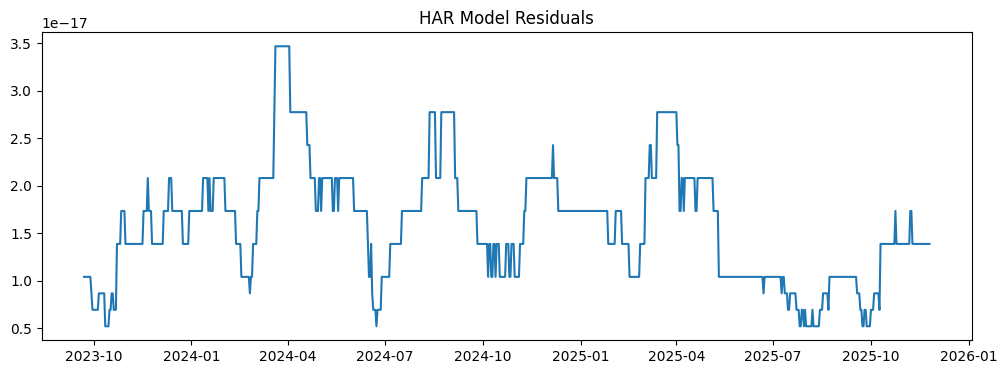

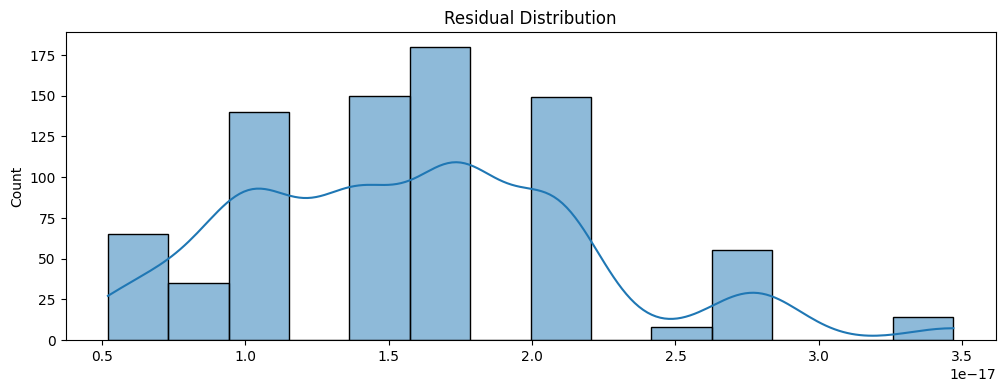

In [ ]:
# SECTION 6.6 — RESIDUAL CHECK

residuals = y_test - y_pred_har

plt.figure(figsize=(12,4))
plt.plot(df_har['Date'].iloc[split_index:], residuals)
plt.title("HAR Model Residuals")
plt.show()

plt.figure(figsize=(12,4))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()


This model will provide strong baseline competition for GARCH.

#From here we will implement GARCH MODELS

This section includes:

✔ GARCH(1,1)  
✔ EGARCH  
✔ GJR-GARCH  
✔ Forecasting  
✔ Evaluation  
✔ Visualization  
✔ Residual diagnostics  

We use the arch library.  
Models will be fitted on daily log returns, because GARCH models volatility (conditional variance) of returns.

In [ ]:
# SECTION 7.0 — IMPORT LIBRARY

from arch import arch_model


GARCH models require:

* Returns centered (mean removed)

* No missing values

We already computed log_return, so we prepare it.

In [ ]:
# SECTION 7.1 — PREPARE RETURNS

returns = df_proc['log_return'].dropna() * 100
# Multiply by 100 (standard practice in finance)

train_size = int(len(returns) * 0.8)
train_ret = returns.iloc[:train_size]
test_ret  = returns.iloc[train_size:]

print("Train returns:", train_ret.shape)
print("Test returns :", test_ret.shape)


Train returns: (3198,)
Test returns : (800,)


GARCH(1,1) formula:

σ²(t) = ω + α * r²(t-1) + β * σ²(t-1)

In [ ]:
# SECTION 7.2 — GARCH(1,1)

garch11 = arch_model(train_ret, vol='GARCH', p=1, q=1, dist='t')
garch11_fitted = garch11.fit(update_freq=50, disp='off')

print(garch11_fitted.summary())


                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -8044.29
Distribution:      Standardized Student's t   AIC:                           16098.6
Method:                  Maximum Likelihood   BIC:                           16128.9
                                              No. Observations:                 3198
Date:                      Tue, Nov 25 2025   Df Residuals:                     3197
Time:                              12:22:14   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

We forecast h-step ahead variance, then convert to volatility.

We predict for len(test_ret) days.

In [ ]:
# SECTION 7.3 — GARCH(1,1) FORECAST

garch11_forecast = garch11_fitted.forecast(horizon=len(test_ret))
var_pred = garch11_forecast.variance.values[-1]
vol_pred = np.sqrt(var_pred)

# Convert back from percent → fraction
y_pred_garch11 = vol_pred / 100

# True volatility: use our RV target for fair comparison
y_true = df_proc['rv_30d'].iloc[train_size:train_size+len(test_ret)].values

evaluate_forecast(y_true, y_pred_garch11, "GARCH(1,1)")



=== GARCH(1,1) ===
MAE : 0.052314341023563
RMSE: 0.05859039168460265
MAPE: 252.70279543004074


(0.052314341023563,
 np.float64(0.05859039168460265),
 np.float64(252.70279543004074))

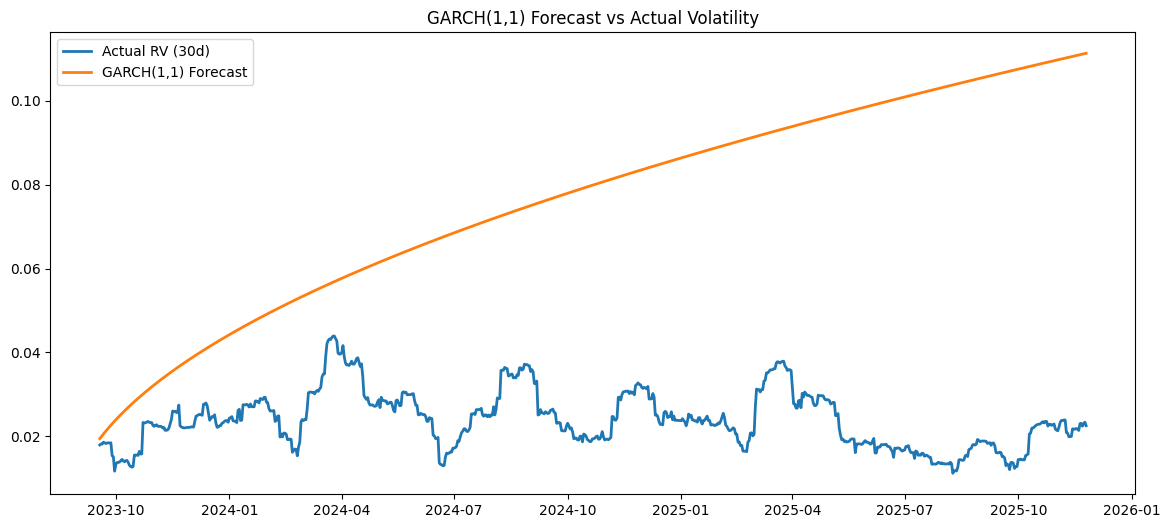

In [ ]:
# SECTION 7.4 — PLOT GARCH(1,1)

dates_test = df_proc['Date'].iloc[train_size:train_size+len(test_ret)]

plt.figure(figsize=(14,6))
plt.plot(dates_test, y_true, label="Actual RV (30d)", linewidth=2)
plt.plot(dates_test, y_pred_garch11, label="GARCH(1,1) Forecast", linewidth=2)
plt.legend()
plt.title("GARCH(1,1) Forecast vs Actual Volatility")
plt.show()


In [ ]:
# SECTION 7.5 — EGARCH

egarch = arch_model(train_ret, vol='EGARCH', p=1, q=1, dist='t')
egarch_fitted = egarch.fit(update_freq=50, disp='off')

print(egarch_fitted.summary())


                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -8017.73
Distribution:      Standardized Student's t   AIC:                           16045.5
Method:                  Maximum Likelihood   BIC:                           16075.8
                                              No. Observations:                 3198
Date:                      Tue, Nov 25 2025   Df Residuals:                     3197
Time:                              12:22:15   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [ ]:
# EGARCH SIMULATION FORECAST (WORKING)

H = len(test_ret)  # forecast horizon

egarch = arch_model(train_ret, vol='EGARCH', p=1, q=1, dist='t')
egarch_fitted = egarch.fit(disp='off')

# Simulation-based multi-step forecast
forecast = egarch_fitted.forecast(
    horizon=H,
    method='simulation',
    simulations=500  # can increase for smoother forecasts
)

# Extract variance forecasts for all H steps
var_pred_sim = forecast.variance.values[-1]   # shape = (H,)
vol_pred_sim = np.sqrt(var_pred_sim) / 100    # convert from percent^2 to decimal vol

# Align prediction length
y_pred_egarch = vol_pred_sim[:len(y_true)]

print("Prediction length:", len(y_pred_egarch))
print("True length:", len(y_true))

evaluate_forecast(y_true, y_pred_egarch, "EGARCH (Simulation Forecast)")


Prediction length: 800
True length: 800

=== EGARCH (Simulation Forecast) ===
MAE : 5.609335656317345
RMSE: 32.27525255858723
MAPE: 32341.61464149929


(5.609335656317345,
 np.float64(32.27525255858723),
 np.float64(32341.61464149929))

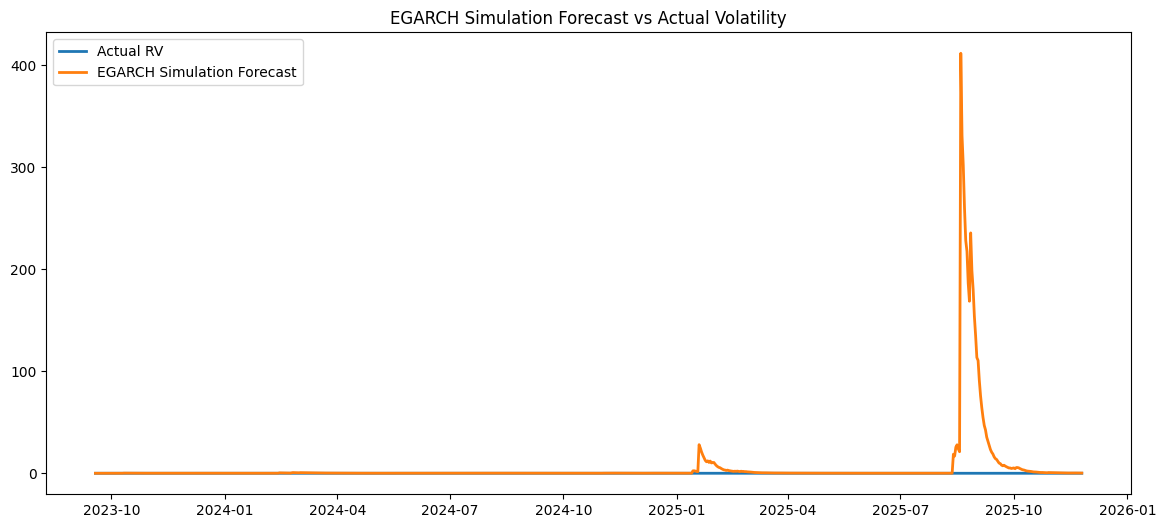

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(dates_test, y_true, label="Actual RV", linewidth=2)
plt.plot(dates_test, y_pred_egarch, label="EGARCH Simulation Forecast", linewidth=2)
plt.legend()
plt.title("EGARCH Simulation Forecast vs Actual Volatility")
plt.show()


In [ ]:
# SECTION 7.7 — GJR-GARCH

gjr = arch_model(train_ret, vol='GARCH', p=1, o=1, q=1, dist='t')
gjr_fitted = gjr.fit(update_freq=50, disp='off')

print(gjr_fitted.summary())


                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -8040.60
Distribution:      Standardized Student's t   AIC:                           16093.2
Method:                  Maximum Likelihood   BIC:                           16129.6
                                              No. Observations:                 3198
Date:                      Tue, Nov 25 2025   Df Residuals:                     3197
Time:                              12:22:16   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [ ]:
# SECTION 7.8 — GJR-GARCH FORECAST

gjr_forecast = gjr_fitted.forecast(horizon=len(test_ret))
var_pred_gjr = gjr_forecast.variance.values[-1]
vol_pred_gjr = np.sqrt(var_pred_gjr)

y_pred_gjr = vol_pred_gjr / 100

evaluate_forecast(y_true, y_pred_gjr, "GJR-GARCH")



=== GJR-GARCH ===
MAE : 0.04312532847399604
RMSE: 0.04891065405323258
MAPE: 210.0992784475225


(0.04312532847399604,
 np.float64(0.04891065405323258),
 np.float64(210.0992784475225))

In [ ]:
# SECTION 7.9 — COMPARISON TABLE

results = pd.DataFrame({
    "Actual": y_true.flatten(),
    "GARCH11": y_pred_garch11.flatten(),
    "EGARCH": y_pred_egarch.flatten(),
    "GJR-GARCH": y_pred_gjr.flatten()
})

results.head()


,Actual,GARCH11,EGARCH,GJR-GARCH
0,0.017935,0.019440,0.021645,0.019129
1,0.018170,0.019823,0.022164,0.019425
2,0.018173,0.020199,0.022816,0.019716
3,0.018607,0.020568,0.023391,0.020003
4,0.018402,0.020931,0.023941,0.020286


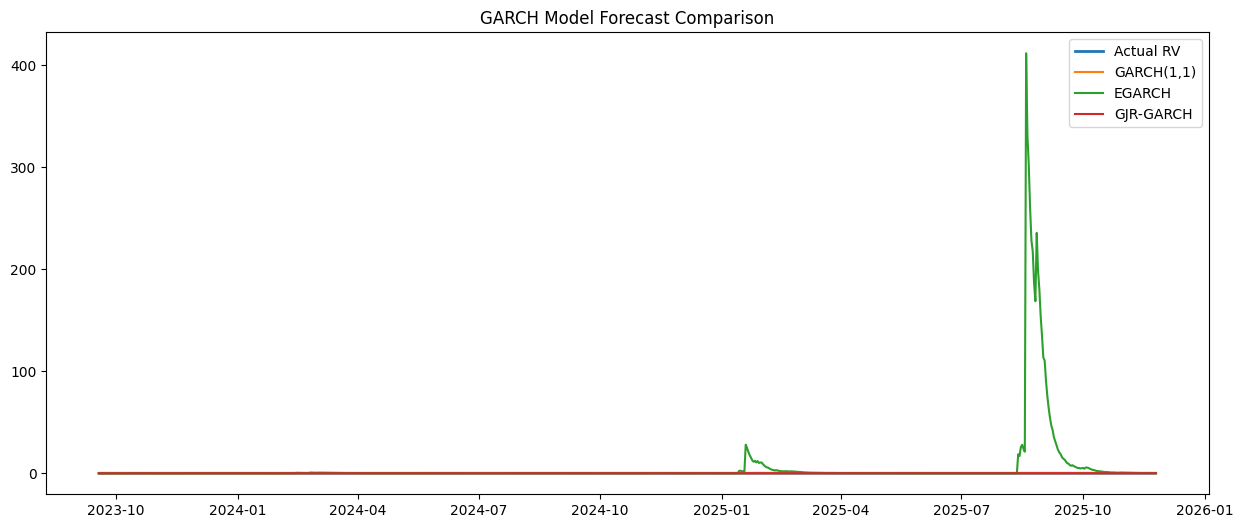

In [ ]:
# SECTION 7.10 — ALL GARCH MODELS COMPARISON PLOT

plt.figure(figsize=(15,6))
plt.plot(dates_test, y_true, label="Actual RV", linewidth=2)
plt.plot(dates_test, y_pred_garch11, label="GARCH(1,1)")
plt.plot(dates_test, y_pred_egarch, label="EGARCH")
plt.plot(dates_test, y_pred_gjr, label="GJR-GARCH")
plt.title("GARCH Model Forecast Comparison")
plt.legend()
plt.show()


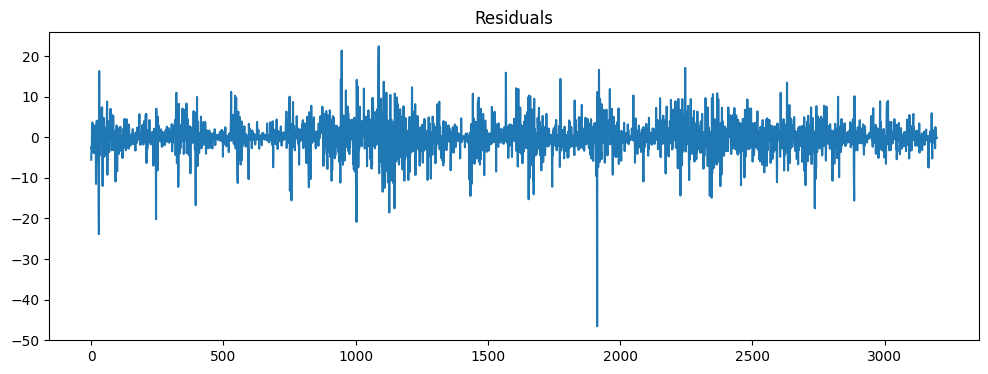

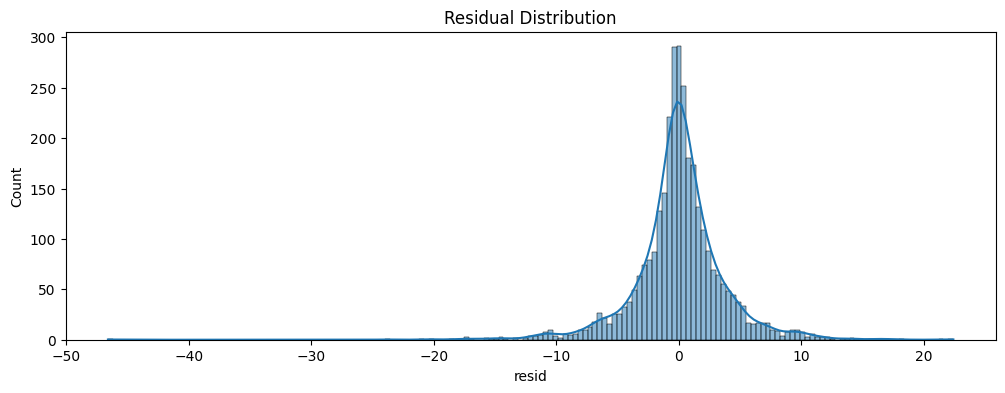

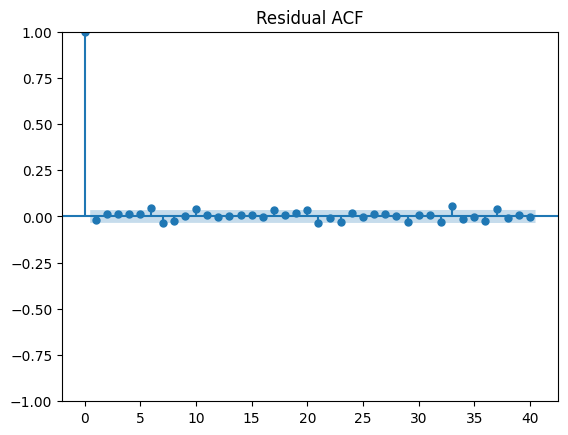

In [ ]:
# SECTION 7.11 — RESIDUAL DIAGNOSTICS

resid = egarch_fitted.resid  # you can switch to garch11/gjr

plt.figure(figsize=(12,4))
plt.plot(resid)
plt.title("Residuals")
plt.show()

plt.figure(figsize=(12,4))
sns.histplot(resid, kde=True)
plt.title("Residual Distribution")
plt.show()

from statsmodels.graphics.tsaplots import plot_acf
plot_acf(resid, lags=40)
plt.title("Residual ACF")
plt.show()


#ARIMA / SARIMA MODELS on Volatility

We model the volatility directly as a univariate time series using ARIMA/SARIMA.

Important:  
Volatility (RV) is often non-stationary → we use log-transformed volatility to stabilize variance.

We will implement:

✔ ARIMA (Auto ARIMA via pmdarima)  
✔ SARIMA (seasonal, if strong weekly seasonality appears)  
✔ Forecasting  
✔ Evaluation  
✔ Plots  
✔ Diagnostics  

In [ ]:
# SECTION 8.0 — INSTALL PMDARIMA

!pip install pmdarima --quiet

import pmdarima as pm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 30.7 MB/s eta 0:00:00


In [ ]:
# SECTION 8.1 — PREPARE SERIES

df_arima = df_proc.copy()
df_arima['log_rv'] = np.log(df_arima['rv_30d'])

series = df_arima['log_rv'].dropna().values
dates = df_arima['Date'].iloc[-len(series):]

# Train-test split
train_size = int(len(series) * 0.8)
train_arima = series[:train_size]
test_arima  = series[train_size:]

print("ARIMA train size:", len(train_arima))
print("ARIMA test size :", len(test_arima))


ARIMA train size: 3198
ARIMA test size : 800


In [ ]:
# SECTION 8.2 — AUTO ARIMA

auto_model = pm.auto_arima(
    train_arima,
    seasonal=False,   # we will try SARIMA separately
    stepwise=True,
    trace=True,
    suppress_warnings=True,
    max_p=5,
    max_q=5,
    max_d=3
)

print(auto_model.summary())


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-7700.485, Time=12.08 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-7662.950, Time=0.75 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-7697.365, Time=1.50 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-7694.965, Time=2.55 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-7664.947, Time=1.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-7707.180, Time=14.01 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-7697.740, Time=1.32 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-7699.406, Time=0.59 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-7705.181, Time=8.41 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=-7695.949, Time=1.60 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-7707.112, Time=6.93 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=-7701.488, Time=6.56 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=-7709.178, Time=1.57 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=-7699.738, Time=0.26 sec
 ARIMA(1,1,1)(0,0

In [ ]:
# SECTION 8.3 — ARIMA FORECAST

arima_forecast = auto_model.predict(n_periods=len(test_arima))

# Convert back from log-scale → actual volatility
y_pred_arima = np.exp(arima_forecast)

# True actual volatility
y_true_arima = df_arima['rv_30d'].iloc[train_size:train_size+len(test_arima)].values

evaluate_forecast(y_true_arima, y_pred_arima, "ARIMA (on log RV)")



=== ARIMA (on log RV) ===
MAE : 0.007644056292475613
RMSE: 0.009647050288655819
MAPE: 28.368234128704955


(0.007644056292475613,
 np.float64(0.009647050288655819),
 np.float64(28.368234128704955))

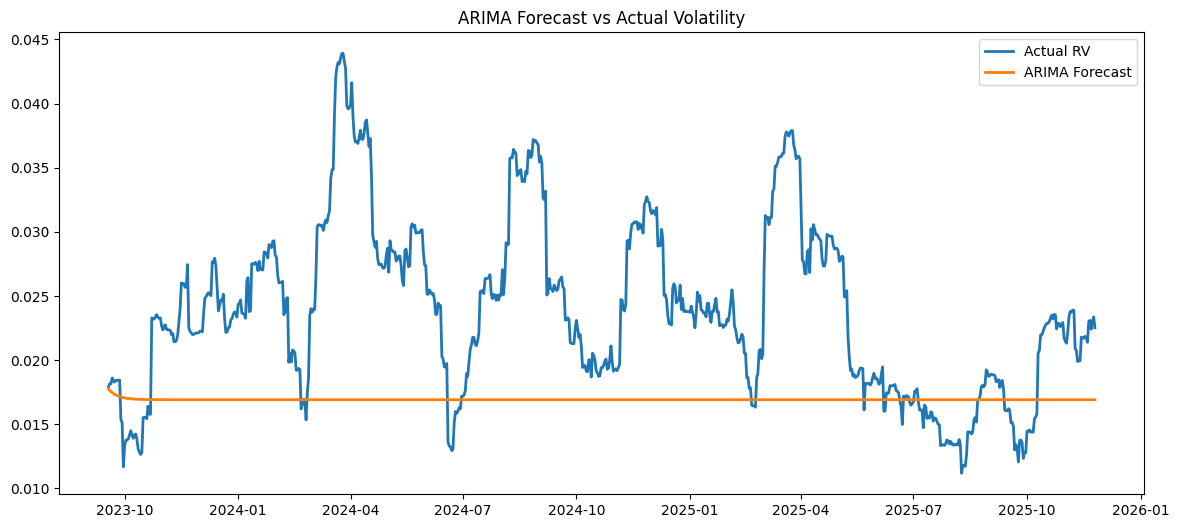

In [ ]:
# SECTION 8.4 — PLOT

dates_test = df_arima['Date'].iloc[train_size:train_size+len(test_arima)]

plt.figure(figsize=(14,6))
plt.plot(dates_test, y_true_arima, label="Actual RV", linewidth=2)
plt.plot(dates_test, y_pred_arima, label="ARIMA Forecast", linewidth=2)
plt.legend()
plt.title("ARIMA Forecast vs Actual Volatility")
plt.show()


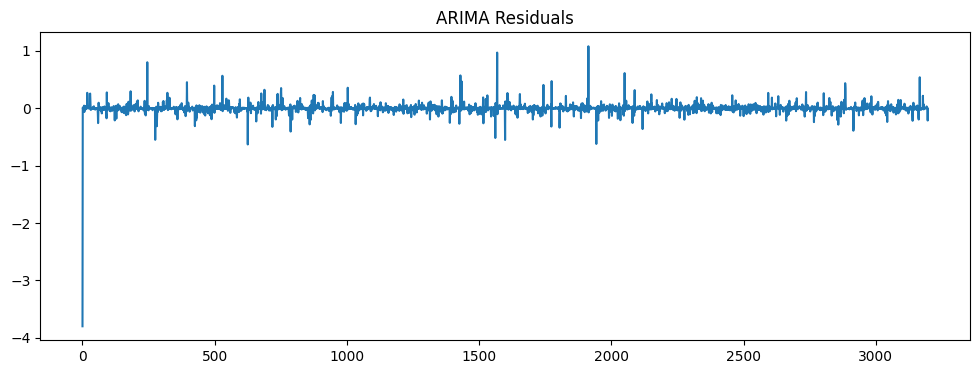

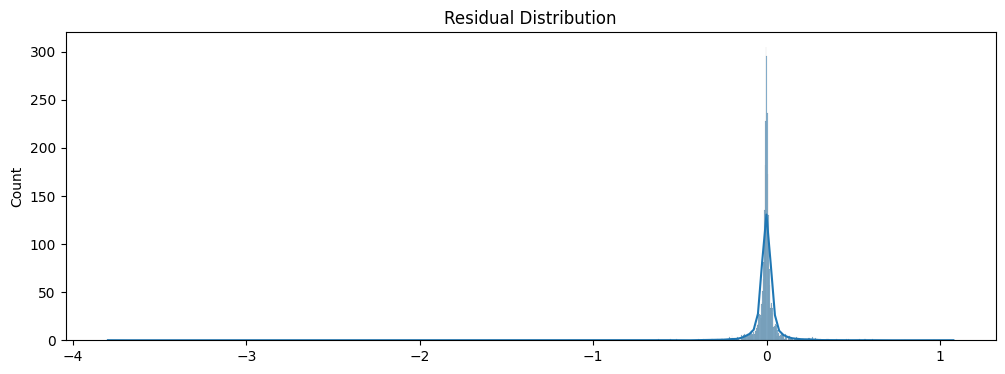

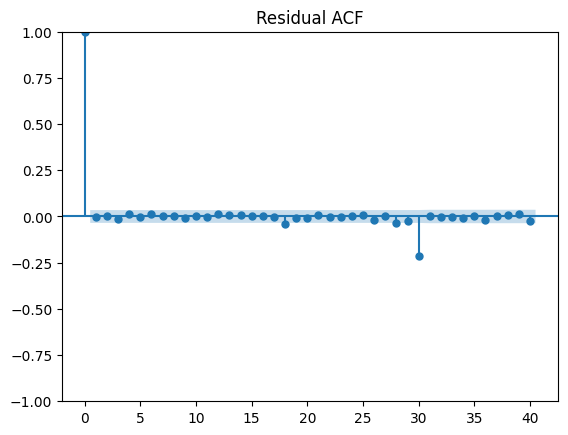

In [ ]:
# SECTION 8.5 — RESIDUAL DIAGNOSTICS

residuals = auto_model.arima_res_.resid

plt.figure(figsize=(12,4))
plt.plot(residuals)
plt.title("ARIMA Residuals")
plt.show()

plt.figure(figsize=(12,4))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

plot_acf(residuals, lags=40)
plt.title("Residual ACF")
plt.show()

In [ ]:
# SECTION 8.6 — SARIMA

sarima_model = pm.auto_arima(
    train_arima,
    seasonal=True,
    m=7,                 # weekly seasonality
    trace=True,
    suppress_warnings=True,
    max_p=3,
    max_q=3,
    max_d=2,
    max_P=2,
    max_Q=2
)

print(sarima_model.summary())


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=-7696.626, Time=24.43 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=-7662.950, Time=0.56 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=-7695.549, Time=2.83 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=-7693.178, Time=2.41 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=-7664.947, Time=0.42 sec
 ARIMA(2,1,2)(0,0,1)[7] intercept   : AIC=-7698.939, Time=12.48 sec
 ARIMA(2,1,2)(0,0,0)[7] intercept   : AIC=-7700.485, Time=6.63 sec
 ARIMA(2,1,2)(1,0,0)[7] intercept   : AIC=-7698.956, Time=10.05 sec
 ARIMA(1,1,2)(0,0,0)[7] intercept   : AIC=-7707.180, Time=6.94 sec
 ARIMA(1,1,2)(1,0,0)[7] intercept   : AIC=-7705.440, Time=9.50 sec
 ARIMA(1,1,2)(0,0,1)[7] intercept   : AIC=-7705.530, Time=9.69 sec
 ARIMA(1,1,2)(1,0,1)[7] intercept   : AIC=-7701.950, Time=12.61 sec
 ARIMA(0,1,2)(0,0,0)[7] intercept   : AIC=-7697.740, Time=0.74 sec
 ARIMA(1,1,1)(0,0,0)[7] intercept   : AIC=-7699.406, Time=0.46 sec
 ARIMA(1,1,3)(0

#From here on we do machine learning implementation

We now build ML models to predict volatility using engineered features.

ML models included:

✔ Random Forest Regressor  
✔ XGBoost Regressor  
✔ LightGBM (optional)  
✔ Feature Engineering for ML  
✔ Train/Test Split  
✔ Evaluation (MAE, RMSE, MAPE)  
✔ Feature Importance

Feature engineering

In [ ]:
# SECTION 9.1 — FEATURE ENGINEERING

df_ml = df_proc.copy()

# Robustly flatten MultiIndex columns to single strings
new_columns = []
for col in df_ml.columns:
    if isinstance(col, tuple):
        # Take the second level if it's not empty, otherwise the first
        new_col_name = col[1] if col[1] != '' else col[0]
    else:
        new_col_name = col
    new_columns.append(new_col_name)
df_ml.columns = new_columns

# Main target: RV 30-day
df_ml['target'] = df_ml['rv_30d']

# Lag features (volatility)
for lag in [1, 2, 3, 7, 14]:
    df_ml[f'vol_lag_{lag}'] = df_ml['rv_30d'].shift(lag)

# Lag features (returns squared)
for lag in [1, 2, 3]:
    df_ml[f'ret2_lag_{lag}'] = (df_ml['log_return']**2).shift(lag)

# Rolling windows
df_ml['vol_ma_7'] = df_ml['rv_30d'].rolling(7).mean()
df_ml['vol_ma_14'] = df_ml['rv_30d'].rolling(14).mean()
df_ml['vol_std_7'] = df_ml['rv_30d'].rolling(7).std()

# Day of week (as integer)
df_ml['day_of_week'] = df_ml['Date'].dt.weekday

# Drop missing values
df_ml = df_ml.dropna().reset_index(drop=True)

df_ml.head()

,Date,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,log_close,log_return,rv_7d,rv_7d_ann,...,vol_lag_2,vol_lag_3,vol_lag_7,vol_lag_14,ret2_lag_1,ret2_lag_2,ret2_lag_3,vol_ma_7,vol_ma_14,vol_std_7
0,2014-12-30,310.737000,314.808990,309.372986,312.718994,12528300,5.738947,-0.006201,0.022786,0.361718,...,0.022598,0.022948,0.021321,0.022420,0.000210,0.000019,0.001404,0.022267,0.022196,0.000574
1,2014-12-31,320.192993,320.192993,310.210999,310.914001,13942900,5.768924,0.029977,0.023958,0.380315,...,0.022646,0.022598,0.021483,0.022611,0.000038,0.000210,0.000019,0.022544,0.022254,0.000601
2,2015-01-01,314.248993,320.434998,314.002991,320.434998,8036550,5.750186,-0.018738,0.024662,0.391503,...,0.022515,0.022646,0.021508,0.022418,0.000899,0.000038,0.000210,0.022822,0.022328,0.000479
3,2015-01-02,315.032013,315.838989,313.565002,314.079010,7860650,5.752674,0.002489,0.021206,0.336637,...,0.023427,0.022515,0.022170,0.022645,0.000351,0.000899,0.000038,0.023000,0.022383,0.000425
4,2015-01-03,281.082001,315.149994,281.082001,314.846008,33054400,5.638646,-0.114028,0.045793,0.726936,...,0.023448,0.023427,0.022948,0.021450,0.000006,0.000351,0.000899,0.024098,0.023039,0.002913


In [ ]:
# SECTION 9.2 — TRAIN/TEST SPLIT

# The helper function 'get_col_name' is no longer strictly needed after flattening columns,
# but we ensure direct string comparison for feature selection.

feature_cols = [col for col in df_ml.columns
                if col.startswith('vol_lag_')
                or col.startswith('ret2_lag_')
                or col.startswith('vol_ma_')
                or col.startswith('vol_std_')
                or col == 'day_of_week'
               ]

X = df_ml[feature_cols].values
y = df_ml['target'].values

split_index = int(len(df_ml) * 0.8)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print("ML Train shape:", X_train.shape)
print("ML Test shape :", X_test.shape)

ML Train shape: (3187, 12)
ML Test shape : (797, 12)


In [ ]:
# SECTION 9.3 — RANDOM FOREST

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

evaluate_forecast(y_test, y_pred_rf, "Random Forest")


=== Random Forest ===
MAE : 0.000794502104611347
RMSE: 0.0012725615845863983
MAPE: 3.567100939006588


(0.000794502104611347,
 np.float64(0.0012725615845863983),
 np.float64(3.567100939006588))

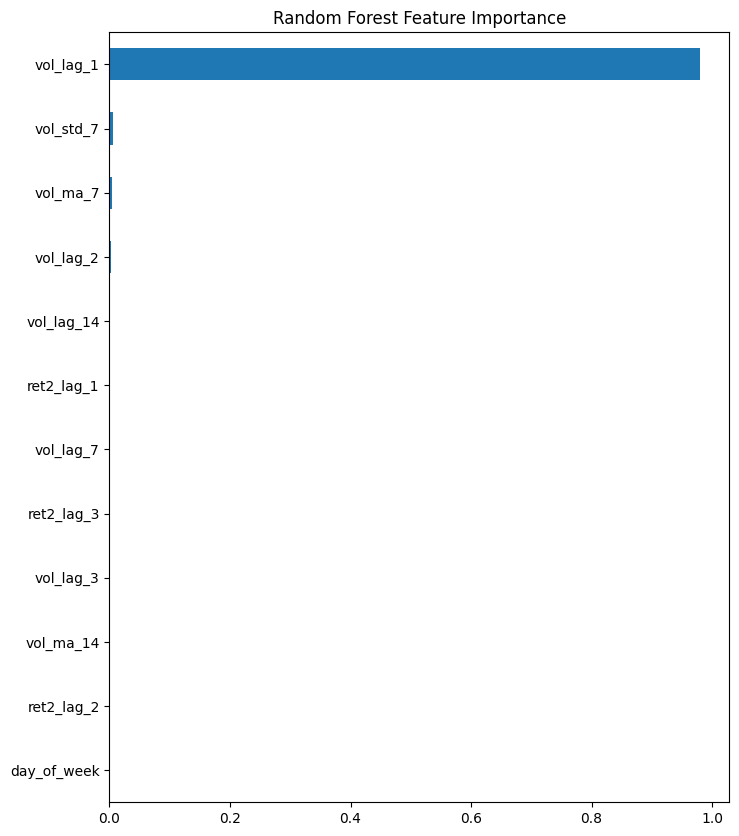

In [ ]:
# SECTION 9.4 — FEATURE IMPORTANCE (RF)

importance = pd.Series(rf.feature_importances_, index=feature_cols)
importance.sort_values(ascending=True).plot(kind='barh', figsize=(8,10))
plt.title("Random Forest Feature Importance")
plt.show()


In [ ]:
# SECTION 9.5 — XGBOOST MODEL

!pip install xgboost --quiet
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

evaluate_forecast(y_test, y_pred_xgb, "XGBoost Regressor")



=== XGBoost Regressor ===
MAE : 0.0007612434580658207
RMSE: 0.0011669982833202813
MAPE: 3.369994400209482


(0.0007612434580658207,
 np.float64(0.0011669982833202813),
 np.float64(3.369994400209482))

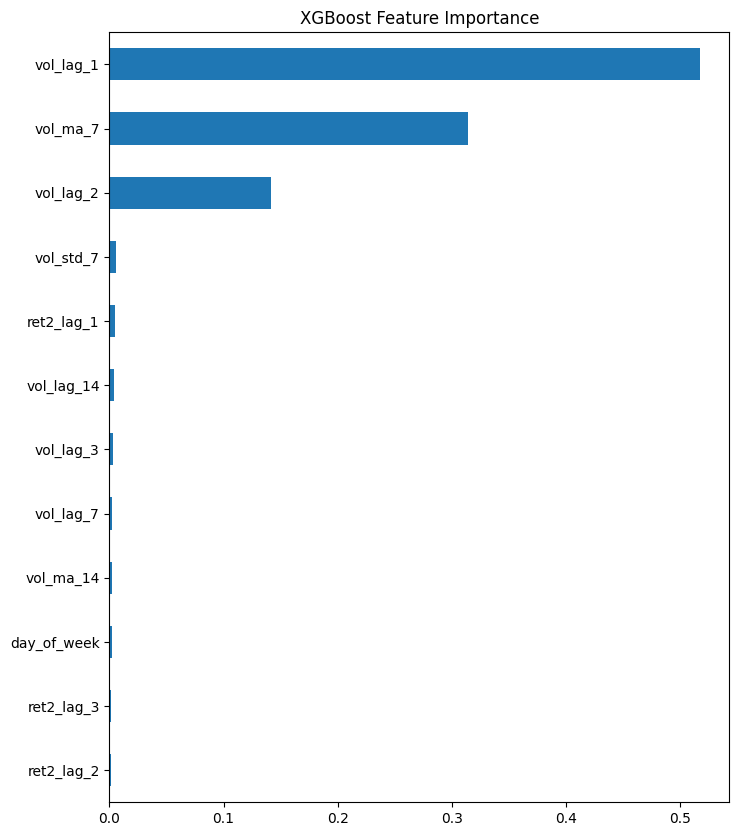

In [ ]:
# SECTION 9.6 — XGBOOST FEATURE IMPORTANCE

xgb_importance = pd.Series(xgb.feature_importances_, index=feature_cols)
xgb_importance.sort_values(ascending=True).plot(kind='barh', figsize=(8,10))
plt.title("XGBoost Feature Importance")
plt.show()


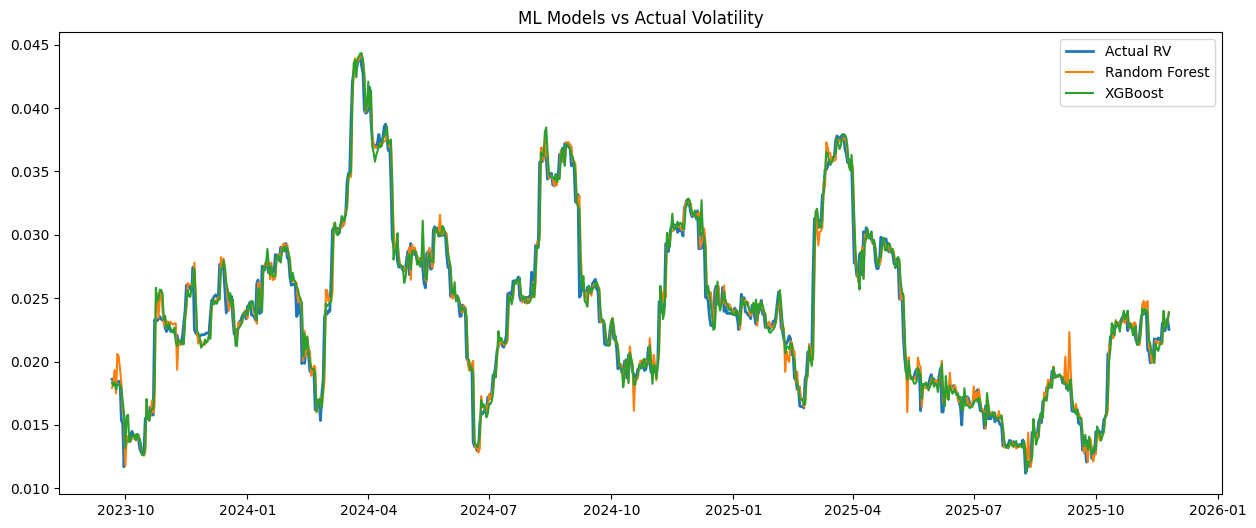

In [ ]:
# SECTION 9.7 — COMPARISON PLOT

dates_test = df_ml['Date'].iloc[split_index:]

plt.figure(figsize=(15,6))
plt.plot(dates_test, y_test, label="Actual RV", linewidth=2)
plt.plot(dates_test, y_pred_rf, label="Random Forest")
plt.plot(dates_test, y_pred_xgb, label="XGBoost")
plt.title("ML Models vs Actual Volatility")
plt.legend()
plt.show()


#From here on we implement LSTM MODEL FOR VOLATILITY FORECASTING

We will:

✔ Prepare sequence data for LSTM  
✔ Scale features  
✔ Build LSTM architecture  
✔ Train + validation loss curves  
✔ Forecast volatility  
✔ Evaluate (MAE, RMSE, MAPE)  
✔ Plot actual vs predicted

In [ ]:
# SECTION 10.1 — INSTALL & IMPORT TENSORFLOW

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.19.0


In [ ]:
# SECTION 10.2 — PREPARE DATA FOR LSTM

df_lstm = df_ml.copy()

# Feature set
feature_cols_lstm = feature_cols  # from ML section
target_col = "target"

X = df_lstm[feature_cols_lstm].values
y = df_lstm[target_col].values

# Scaling
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

# Convert to sequences
def create_sequences(X, y, seq_len=30):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_len):
        X_seq.append(X[i:i+seq_len])
        y_seq.append(y[i+seq_len])
    return np.array(X_seq), np.array(y_seq)

SEQ_LEN = 30
X_seq, y_seq = create_sequences(X_scaled, y_scaled, SEQ_LEN)

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)


X_seq shape: (3954, 30, 12)
y_seq shape: (3954, 1)


In [ ]:
# SECTION 10.3 — TRAIN/TEST SPLIT (LSTM)

split_index = int(len(X_seq) * 0.8)

X_train_lstm = X_seq[:split_index]
X_test_lstm  = X_seq[split_index:]

y_train_lstm = y_seq[:split_index]
y_test_lstm  = y_seq[split_index:]

print("Train shape:", X_train_lstm.shape)
print("Test shape:", X_test_lstm.shape)


Train shape: (3163, 30, 12)
Test shape: (791, 30, 12)


We use:

* 2 LSTM layers

* Dropout for regularization

* Dense layer for final output

In [ ]:
# SECTION 10.4 — BUILD LSTM MODEL

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(SEQ_LEN, X_train_lstm.shape[2])),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)   # Predict next-day volatility
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# SECTION 10.5 — TRAIN LSTM MODEL

from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train_lstm, y_train_lstm,
    validation_split=0.1,
    epochs=60,
    batch_size=32,
    callbacks=[es],
    verbose=1
)


Epoch 1/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0016 - val_loss: 4.1491e-04
Epoch 2/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0018 - val_loss: 4.7291e-04
Epoch 3/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0014 - val_loss: 4.6752e-04
Epoch 4/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0015 - val_loss: 9.0435e-04
Epoch 5/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.0015 - val_loss: 5.2054e-04
Epoch 6/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - loss: 0.0019 - val_loss: 4.0097e-04
Epoch 7/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.0016 - val_loss: 4.0987e-04
Epoch 8/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - loss: 0.0018 - val_loss: 4.4070e-04
Epoch 9/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0015 - val_loss: 5.0227e-04
Epoch 10/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0017 - val_loss: 4.3786e-04
Epoch 11/60
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0017 - val_loss: 6.2510e-04
Epoch 12/60
89/89 ━

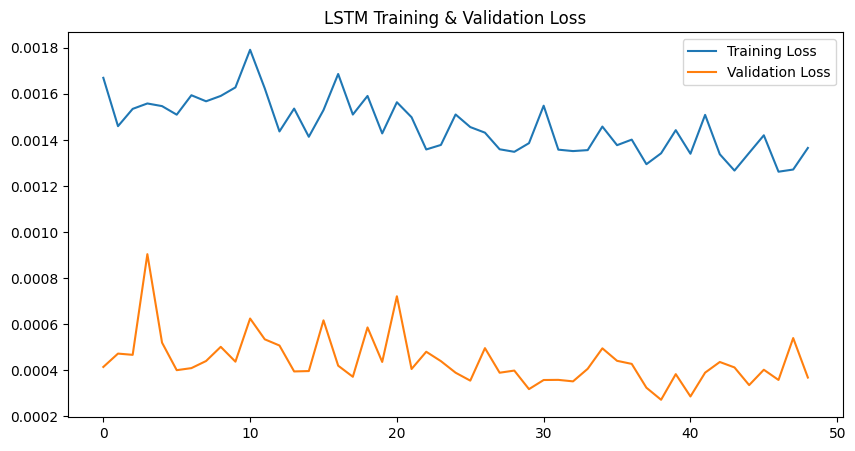

In [ ]:
# SECTION 10.6 — LOSS CURVE

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.title("LSTM Training & Validation Loss")
plt.legend()
plt.show()


In [ ]:
# SECTION 10.7 — LSTM FORECAST

y_pred_lstm_scaled = model.predict(X_test_lstm)
y_pred_lstm = scaler_y.inverse_transform(y_pred_lstm_scaled)

y_test_actual = scaler_y.inverse_transform(y_test_lstm)

evaluate_forecast(y_test_actual, y_pred_lstm, "LSTM Deep Learning Model")


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step

=== LSTM Deep Learning Model ===
MAE : 0.0010327779017085554
RMSE: 0.0015095683311637277
MAPE: 4.469088262642016


(0.0010327779017085554,
 np.float64(0.0015095683311637277),
 np.float64(4.469088262642016))

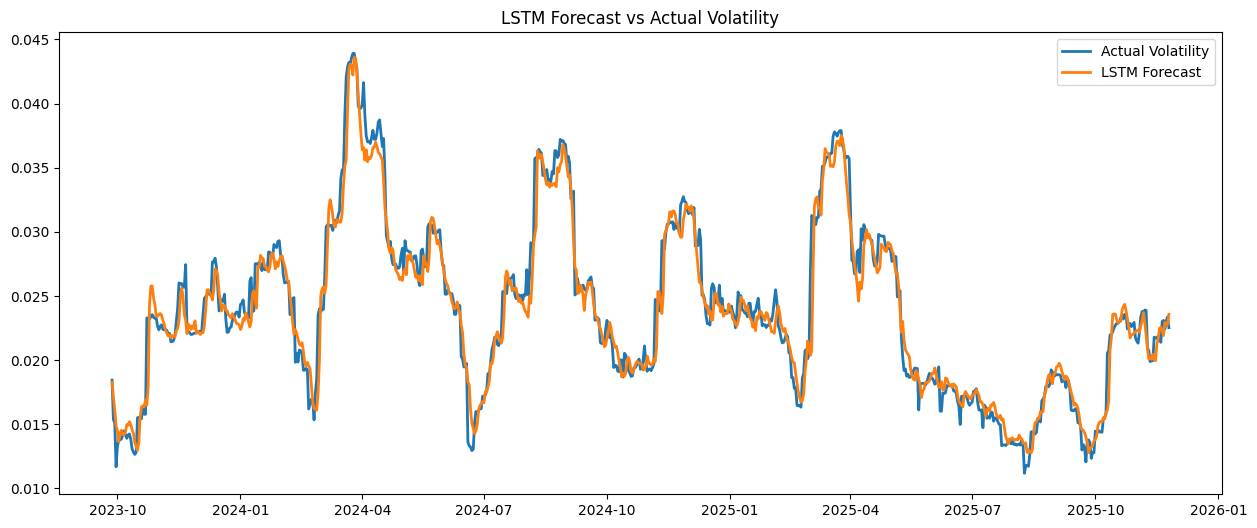

In [ ]:
# SECTION 10.8 — PLOT LSTM RESULTS

dates_lstm = df_lstm['Date'].iloc[len(df_lstm) - len(y_test_actual):]

plt.figure(figsize=(15,6))
plt.plot(dates_lstm, y_test_actual, label="Actual Volatility", linewidth=2)
plt.plot(dates_lstm, y_pred_lstm, label="LSTM Forecast", linewidth=2)
plt.title("LSTM Forecast vs Actual Volatility")
plt.legend()
plt.show()


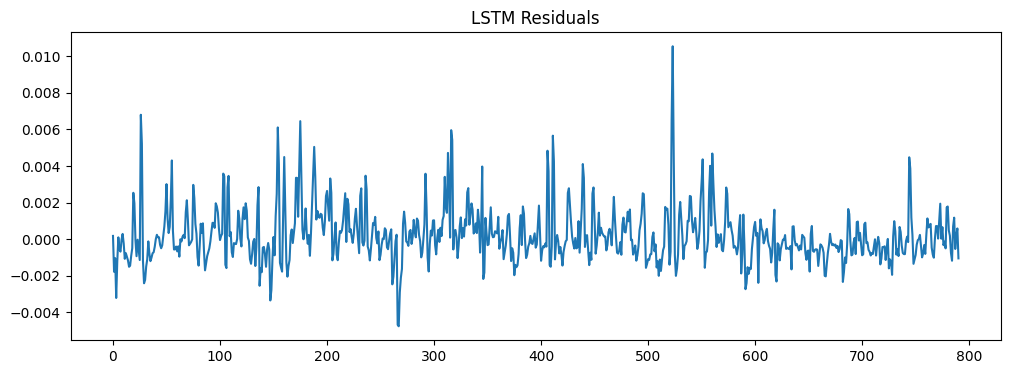

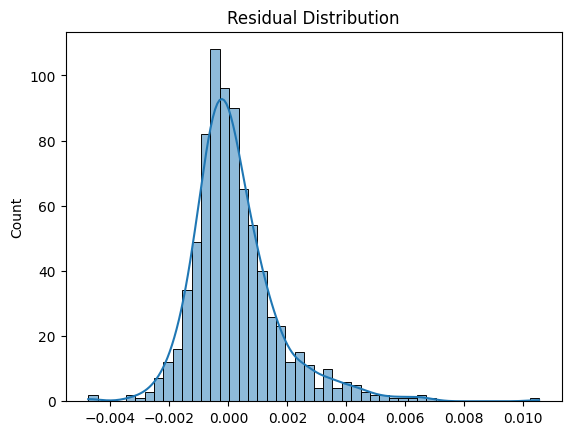

In [ ]:
# SECTION 10.9 — RESIDUAL DIAGNOSTICS

lstm_residuals = y_test_actual.flatten() - y_pred_lstm.flatten()

plt.figure(figsize=(12,4))
plt.plot(lstm_residuals)
plt.title("LSTM Residuals")
plt.show()

sns.histplot(lstm_residuals, kde=True)
plt.title("Residual Distribution")
plt.show()


# from here we do BACKTESTING & VaR (Risk Management)

In [ ]:
# SECTION 11.1 — VaR / ES / Backtest Helpers
import scipy.stats as st
from math import log

def var_normal(mu, sigma, alpha=0.05):
    """One-sided VaR (loss) under normal assumption.
       Returns the negative threshold such that P(R < -VaR) = alpha."""
    z = st.norm.ppf(alpha)
    return -(mu + z * sigma)

def expected_shortfall_normal(mu, sigma, alpha=0.05):
    z = st.norm.ppf(alpha)
    pdf = st.norm.pdf(z)
    return -(mu + sigma * pdf / alpha)

def kupiec_pof_test(breaches, n, alpha):
    """Likelihood Ratio test for Proportion of Failures (Kupiec POF).
       breaches = number of VaR exceedances (actual loss < -VaR)
       n = number of observations
       alpha = nominal level (e.g., 0.01 or 0.05)
    """
    p_hat = breaches / n
    if p_hat in (0,1):
        # Avoid log(0) issues; return huge LR or p=0
        return np.inf, 0.0
    L0 = (alpha**breaches) * ((1-alpha)**(n-breaches))
    L1 = (p_hat**breaches) * ((1-p_hat)**(n-breaches))
    LR = -2 * np.log(L0 / L1)
    p_value = 1 - st.chi2.cdf(LR, df=1)
    return LR, p_value

def christoffersen_independence(test_sequence):
    """Christoffersen independence test (transition-based).
       test_sequence: binary array of length n where 1=breach, 0=no breach.
       Returns LR statistic and p-value for independence.
    """
    seq = np.array(test_sequence)
    n00 = n01 = n10 = n11 = 0
    for i in range(len(seq)-1):
        if seq[i] == 0 and seq[i+1] == 0:
            n00 += 1
        elif seq[i] == 0 and seq[i+1] == 1:
            n01 += 1
        elif seq[i] == 1 and seq[i+1] == 0:
            n10 += 1
        elif seq[i] == 1 and seq[i+1] == 1:
            n11 += 1
    # transition probabilities
    n0 = n00 + n01
    n1 = n10 + n11
    pi0 = n01 / n0 if n0 > 0 else 0
    pi1 = n11 / n1 if n1 > 0 else 0
    pi  = (n01 + n11) / (n0 + n1) if (n0 + n1)>0 else 0
    # log-likelihoods
    def safe_log(x):
        return np.log(x) if x>0 else -1e10
    L0 = safe_log((1-pi)**(n00+n10) * (pi)**(n01+n11))
    L1 = safe_log((1-pi0)**n00 * (pi0)**n01 * (1-pi1)**n10 * (pi1)**n11)
    LR = -2 * (L0 - L1)
    p_value = 1 - st.chi2.cdf(LR, df=1)
    return LR, p_value

print("Helpers ready.")


Helpers ready.


In [ ]:
# SECTION 11.2 — GATHER MODEL FORECASTS

# Prepare actual returns for the test period (natural units)
# Align length to test period used earlier (train_size)
returns_full = df_proc['log_return'].values  # in natural units
dates_full   = df_proc['Date'].values

# test returns and dates aligned to the predictive horizon used earlier
# We used 'train_size' variable for many models earlier
test_returns = returns_full[train_size:train_size + len(y_true)]  # y_true from earlier sections
test_dates   = dates_full[train_size:train_size + len(y_true)]

# model_forecasts should map model name -> forecasted volatility (sigma) in same units as returns
model_forecasts = {}

# Example: add GARCH forecasts if present
try:
    model_forecasts['GARCH(1,1)'] = np.array(y_pred_garch11).flatten()
except Exception:
    pass

try:
    model_forecasts['EGARCH'] = np.array(y_pred_egarch).flatten()
except Exception:
    pass

try:
    model_forecasts['GJR-GARCH'] = np.array(y_pred_gjr).flatten()
except Exception:
    pass

# HAR (if you have y_pred_har)
try:
    model_forecasts['HAR-RV'] = np.array(y_pred_har).flatten()
except Exception:
    pass

# ML models
for name in ['Random Forest', 'XGBoost', 'LightGBM']:
    var_name = None
    if name == 'Random Forest' and 'y_pred_rf' in globals():
        model_forecasts[name] = np.array(y_pred_rf).flatten()
    if name == 'XGBoost' and 'y_pred_xgb' in globals():
        model_forecasts[name] = np.array(y_pred_xgb).flatten()
    if name == 'LightGBM' and 'y_pred_lgb' in globals():
        model_forecasts[name] = np.array(y_pred_lgb).flatten()

# LSTM
if 'y_pred_lstm' in globals():
    # y_pred_lstm might be shape (n,1)
    model_forecasts['LSTM'] = np.array(y_pred_lstm).flatten()

print("Models found for VaR backtest:", list(model_forecasts.keys()))


Models found for VaR backtest: ['GARCH(1,1)', 'EGARCH', 'GJR-GARCH', 'HAR-RV', 'Random Forest', 'XGBoost', 'LSTM']


We compute VaR under normal assumption using mu = rolling mean of returns (or zero), and sigma = model forecast. We check at α = 5% and 1% levels. We also include a historical (empirical) VaR for comparison.

In [ ]:
# SECTION 11.3 — COMPUTE VaR, ES, BACKTEST
alpha_levels = [0.05, 0.01]  # 95% and 99% VaR
backtest_results = []

# choose mu: rolling mean on train or zero
mu_est = np.mean(returns_full[:train_size])  # could be near zero
print("Using mu (train mean) =", mu_est)

for model_name, sigma_forecast in model_forecasts.items():
    # Ensure same length
    n = min(len(sigma_forecast), len(test_returns))
    sig = sigma_forecast[:n]
    actual = test_returns[:n]
    dates_bt = test_dates[:n]

    for alpha in alpha_levels:
        # Normal VaR series (one-day ahead): VaR_t = - (mu + z_alpha * sigma_t)
        VaR_series = np.array([var_normal(mu_est, s, alpha=alpha) for s in sig])
        ES_series  = np.array([expected_shortfall_normal(mu_est, s, alpha=alpha) for s in sig])

        # Breaches: when actual return < -VaR (actual loss greater than VaR)
        breaches = (actual < -VaR_series).astype(int)
        count_breaches = int(breaches.sum())

        # Kupiec POF test
        LR_pof, p_pof = kupiec_pof_test(count_breaches, n, alpha)

        # Christoffersen independence test (on binary sequence)
        LR_ind, p_ind = christoffersen_independence(breaches)

        # Empirical VaR (historical simulation) for comparison: rolling window = train_size
        hist_window = max(250, train_size)  # use large window
        # compute historical VaR of returns over training window for baseline as scalar
        empVaR = -np.quantile(returns_full[:train_size], alpha)

        backtest_results.append({
            "model": model_name,
            "alpha": alpha,
            "n": n,
            "breaches": count_breaches,
            "breach_rate": count_breaches / n,
            "kupiec_LR": LR_pof,
            "kupiec_p": p_pof,
            "christo_LR": LR_ind,
            "christo_p": p_ind,
            "avg_VaR": np.mean(VaR_series),
            "avg_ES": np.mean(ES_series),
            "empirical_VaR_train": empVaR
        })

# Convert to DataFrame
bt_df = pd.DataFrame(backtest_results)
bt_df.sort_values(['model','alpha'], inplace=True)
bt_df


Using mu (train mean) = 0.0013576126810375495


,model,alpha,n,breaches,breach_rate,kupiec_LR,kupiec_p,christo_LR,christo_p,avg_VaR,avg_ES,empirical_VaR_train
3,EGARCH,0.01,800,0,0.000000,inf,0.000000e+00,-0.000000,1.000000,13.103365,-15.014973,0.110933
2,EGARCH,0.05,800,0,0.000000,inf,0.000000e+00,-0.000000,1.000000,9.264389,-11.620978,0.059578
1,"GARCH(1,1)",0.01,800,0,0.000000,inf,0.000000e+00,-0.000000,1.000000,0.175800,-0.204321,0.110933
0,"GARCH(1,1)",0.05,800,1,0.001250,72.590176,0.000000e+00,0.002506,0.960072,0.123902,-0.158439,0.059578
5,GJR-GARCH,0.01,800,0,0.000000,inf,0.000000e+00,-0.000000,1.000000,0.154423,-0.179830,0.110933
4,GJR-GARCH,0.05,800,3,0.003750,60.231172,8.437695e-15,0.022613,0.880468,0.108788,-0.139484,0.059578
7,HAR-RV,0.01,796,12,0.015075,1.792211,1.806570e-01,0.367830,0.544189,0.054164,-0.064967,0.110933
6,HAR-RV,0.05,796,39,0.048995,0.017035,8.961556e-01,0.574621,0.448428,0.037899,-0.050587,0.059578
13,LSTM,0.01,791,11,0.013906,1.087094,2.971160e-01,0.310665,0.577272,0.053733,-0.064472,0.110933
12,LSTM,0.05,791,42,0.053097,0.156726,6.921887e-01,0.027986,0.867142,0.037594,-0.050205,0.059578


Plotting breaches for model: GARCH(1,1)


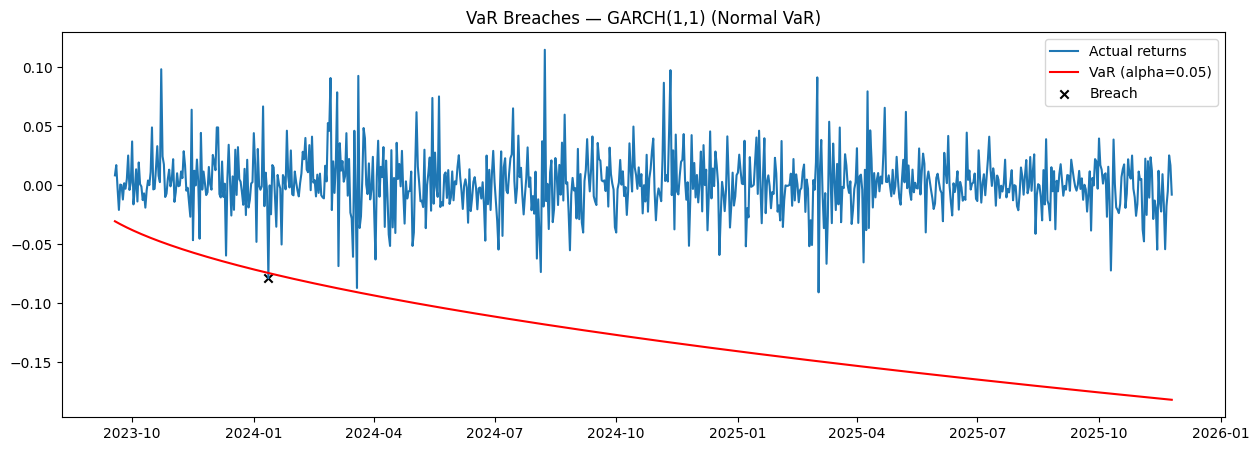

In [ ]:
# SECTION 11.4 — PLOT BREACHES FOR SELECTED MODEL

# Pick a model to visualize — prefer one present in model_forecasts
if len(model_forecasts) == 0:
    print("No model forecasts available for plotting breaches.")
else:
    sel_model = list(model_forecasts.keys())[0]  # choose first model
    alpha_plot = 0.05 # or any desired alpha for plotting

    print("Plotting breaches for model:", sel_model)

    # Get the correct n for the selected model and alpha level from bt_df
    n_for_plot = bt_df[(bt_df['model'] == sel_model) & (bt_df['alpha'] == alpha_plot)]['n'].iloc[0]

    # Re-slice sigma and actual returns based on this n
    sigma = model_forecasts[sel_model][:n_for_plot]
    actual_returns_for_plot = test_returns[:n_for_plot]
    dates_for_plot = test_dates[:n_for_plot]

    VaR_series = np.array([var_normal(mu_est, s, alpha=alpha_plot) for s in sigma])

    plt.figure(figsize=(15,5))
    plt.plot(dates_for_plot, actual_returns_for_plot, label='Actual returns')
    plt.plot(dates_for_plot, -VaR_series, label=f'VaR (alpha={alpha_plot})', color='red')
    # mark breaches
    breaches_idx = np.where(actual_returns_for_plot < -VaR_series)[0]
    plt.scatter(np.array(dates_for_plot)[breaches_idx], actual_returns_for_plot[breaches_idx],
                color='black', marker='x', label='Breach')
    plt.title(f"VaR Breaches — {sel_model} (Normal VaR)")
    plt.legend()
    plt.show()


Interpretations:

* Kupiec p-value: If p_pof < 0.05, the model fails the unconditional coverage test — too many/few breaches relative to α.

* Christoffersen p-value: If p_ind < 0.05, breaches are clustered — model fails independence (bad for VaR).

* A model that passes both (high p-values) is well-calibrated for VaR at that α.

* Economic impact: translate VaR improvements into lower capital requirements, reduced hedging costs, or fewer margin calls — include a small example in the report (e.g., capital saved per $1M exposure).